## Installing required packages

In [1]:
!pip install -q ultralytics huggingface_hub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 7.8 MB/s eta 0:00:00


## Importing required libraries

In [2]:
import os
import cv2
import yaml
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from ultralytics import YOLO
from huggingface_hub import HfApi, login
from kaggle_secrets import UserSecretsClient

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## Environment Setup

In [3]:
BASE_DIR = '/kaggle/input/datasets/mrearthworm/m4-sar/M4-SAR/M4-SAR' #
WORK_DIR = '/kaggle/working/m4_fused'

CLASS_NAMES = {0: 'bridge', 1: 'harbor', 2: 'oil_tank', 3: 'playground', 4: 'airport', 5: 'wind_turbine'} #

## Efficient Data Loader & Early Fusion

In [4]:
def build_fused_dataset(split='train', max_files=2000):
    print(f"\nProcessing {split} split...")
    
    # Exact paths for optical and sar modalities
    opt_img_dir = os.path.join(BASE_DIR, 'optical', 'images', split)
    sar_img_dir = os.path.join(BASE_DIR, 'sar', 'images', split)
    opt_lbl_dir = os.path.join(BASE_DIR, 'optical', 'labels', split)
    
    out_img_dir = os.path.join(WORK_DIR, 'images', split)
    out_lbl_dir = os.path.join(WORK_DIR, 'labels', split)
    os.makedirs(out_img_dir, exist_ok=True)
    os.makedirs(out_lbl_dir, exist_ok=True)
    
    # Using os.scandir
    file_entries = list(os.scandir(opt_img_dir))[:max_files] 
    
    for entry in tqdm(file_entries, desc=f"Fusing {split}"):
        if not entry.name.endswith('.jpg'):
            continue
            
        base_name = entry.name
        txt_name = base_name.replace('.jpg', '.txt')
        
        opt_path = entry.path
        sar_path = os.path.join(sar_img_dir, base_name)
        lbl_path = os.path.join(opt_lbl_dir, txt_name)
        
        if not (os.path.exists(sar_path) and os.path.exists(lbl_path)):
            continue
            
        # Load images
        opt_img = cv2.imread(opt_path) # BGR
        sar_img = cv2.imread(sar_path, cv2.IMREAD_GRAYSCALE) # Redundant channels handled[cite: 2]
        
        if opt_img is None or sar_img is None:
            continue
            
        # Early Fusion
        fused_img = np.dstack((opt_img, sar_img))
        
        # Save as PNG to preserve the 4 channels
        fused_name = base_name.replace('.jpg', '.png')
        cv2.imwrite(os.path.join(out_img_dir, fused_name), fused_img)
        
        # Copy OBB labels
        with open(lbl_path, 'r') as src, open(os.path.join(out_lbl_dir, txt_name), 'w') as dst:
            dst.write(src.read())

# Run the pipeline for Train and Val
build_fused_dataset('train', max_files=2500)
build_fused_dataset('val', max_files=500)

# Create data.yaml for YOLO
yaml_data = {
    'path': WORK_DIR,
    'train': 'images/train',
    'val': 'images/val',
    'nc': 6,
    'names': [CLASS_NAMES[i] for i in range(6)]
}
with open(os.path.join(WORK_DIR, 'data.yaml'), 'w') as f:
    yaml.dump(yaml_data, f)


Processing train split...


Fusing train: 100%|██████████| 2500/2500 [02:15<00:00, 18.47it/s]



Processing val split...


Fusing val: 100%|██████████| 500/500 [00:28<00:00, 17.32it/s]


## Data Validation

Data Validation -> Image Shape: (512, 512, 4) (Expected: 512, 512, 4)


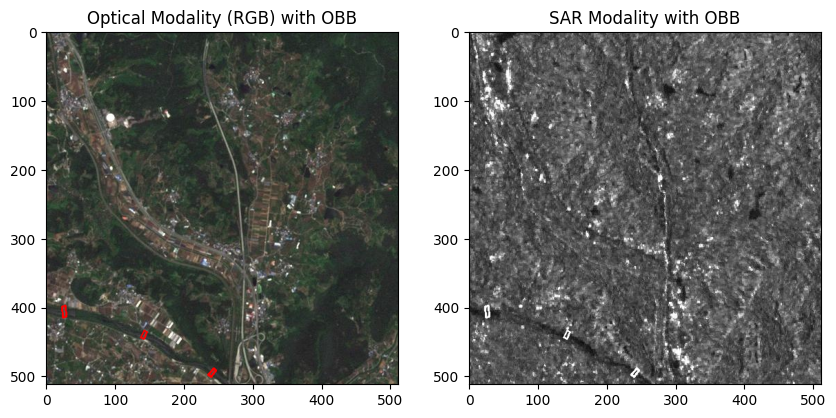

In [5]:
def validate_fused_data():
    sample_img_path = os.path.join(WORK_DIR, 'images', 'train')
    sample_file = next(os.scandir(sample_img_path)).name
    
    img_path = os.path.join(sample_img_path, sample_file)
    lbl_path = os.path.join(WORK_DIR, 'labels', 'train', sample_file.replace('.png', '.txt'))
    
    # Read the 4-channel PNG
    img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
    print(f"Data Validation -> Image Shape: {img.shape} (Expected: 512, 512, 4)")
    
    # Extract Optical (BGR -> RGB) and SAR
    opt_vis = cv2.cvtColor(img[:, :, :3], cv2.COLOR_BGR2RGB).copy()
    sar_vis = img[:, :, 3].copy()
    
    with open(lbl_path, 'r') as f:
        lines = f.readlines()
        
    for line in lines:
        parts = list(map(float, line.strip().split()))
        
        # Denormalize coordinates
        pts = (np.array(parts[1:9]).reshape((-1, 1, 2)) * 512).astype(np.int32)
        
        cv2.polylines(opt_vis, [pts], isClosed=True, color=(255, 0, 0), thickness=2)
        cv2.polylines(sar_vis, [pts], isClosed=True, color=(255,), thickness=2)
        
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    ax1.imshow(opt_vis)
    ax1.set_title("Optical Modality (RGB) with OBB")
    ax2.imshow(sar_vis, cmap='gray')
    ax2.set_title("SAR Modality with OBB")
    plt.show()

validate_fused_data()

## Model Training

In [6]:
# Load the base YOLO-OBB architecture
model = YOLO('yolov8n-obb.pt') 

# Override input channels directly in the model configuration to accept (R, G, B, SAR)
model.yaml['ch'] = 4 

# Train the model 
results = model.train(
    data=os.path.join(WORK_DIR, 'data.yaml'),
    epochs=20,
    imgsz=512,
    batch=16,
    device=0,
    workers=2,
    project='/kaggle/working/runs',
    name='m4_sar_obb_fusion'
)

Ultralytics 8.4.159 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/m4_fused/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-obb.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=m4_sar_obb_fusion, nbs=64, nms=None, 

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/20      2.94G      2.723      3.038      1.361     0.1647         23        512: 100% ━━━━━━━━━━━━ 157/157 4.7it/s 33.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 6.6it/s 4.8s
                   all        499       4505      0.504      0.211      0.192     0.0936

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss angle_loss  Instances       Size
       3/20      2.94G      2.609      2.794      1.306     0.1537         32        512: 100% ━━━━━━━━━━━━ 157/157 4.6it/s 33.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 6.8it/s 4.7s
                   all        499       4505      0.521      0.247      0.206      0.102

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss angle_loss  Instances       Size
       4/20      2.94G      2.503      2.676      1.257     0.1625         20        512: 100% ━━━━━━━━━━━━ 157/157 4.7it/s 33.1

## Evaluation

In [7]:
# Evaluate on validation dataset

print("\n--- CALCULATING METRICS ---")

metrics = model.val(data=os.path.join(WORK_DIR, 'data.yaml'))

print("\nVALIDATION SCORES:")
print(f"mAP@50 (OBB):    {metrics.box.map50:.4f}")
print(f"mAP@50-95 (OBB): {metrics.box.map:.4f}")
print(f"Precision:       {metrics.box.mp:.4f}")
print(f"Recall:          {metrics.box.mr:.4f}")


--- CALCULATING METRICS ---
Ultralytics 8.4.159 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv8n-obb summary (fused): 81 layers, 3,078,389 parameters, 0 gradients, 8.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5149.3±850.9 MB/s, size: 635.1 KB)
val: Scanning /kaggle/working/m4_fused/labels/val.cache... 500 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 500/500 190.7Mit/s 0.0s
val: /kaggle/working/m4_fused/images/val/93992.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.0878]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 4.8it/s 6.6s
                   all        499       4505      0.581      0.353      0.381      0.201
                bridge        392       1946      0.714      0.231      0.314      0.162
                harbor         46        103      0.398      0.302      0.266      0.106
              oil_tank         36       169

## Uploading it to Huggingface

In [8]:
try:
    user_secrets = UserSecretsClient()
    hf_token = user_secrets.get_secret("HF_TOKEN")
    login(token=hf_token)
    
    repo_id = "nillohitroy/m4-sar-yolov8-obb-fused"
    api = HfApi()
    
    print(f"Creating repository: {repo_id}...")
    api.create_repo(repo_id=repo_id, repo_type="model", exist_ok=True)
    
    print("Uploading OBB weights...")
    api.upload_file(
        path_or_fileobj="/kaggle/working/runs/m4_sar_obb_fusion/weights/best.pt",
        path_in_repo="best_yolo_obb.pt",
        repo_id=repo_id,
        repo_type="model"
    )
    print(f"OBB Model pushed successfully to https://huggingface.co/{repo_id}")
    
except Exception as e:
    print(f"Hugging Face upload skipped/failed: {e}")

Creating repository: nillohitroy/m4-sar-yolov8-obb-fused...
Uploading OBB weights...


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

OBB Model pushed successfully to https://huggingface.co/nillohitroy/m4-sar-yolov8-obb-fused
